In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay


In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")
print(X.head())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


test_size = 0.2 : reserves 20% of the data for testing
random_state = 42 : makes the split reproducible
stratify  = y : helps preserve the proportions of the two classes in each set

In [4]:
print('Training features:', X_train.shape)
print('Training labels:', y_train.shape)
print('Testing features:', X_test.shape)
print("Testing labels:", y_test.shape)

Training features: (455, 30)
Training labels: (455,)
Testing features: (114, 30)
Testing labels: (114,)


In [5]:
scaler = StandardScaler()

In [6]:
X_train = scaler.fit_transform(X_train)

In [7]:
X_test = scaler.fit_transform(X_test)

transform() reuses those same values for test data. This prevents information from the test set leaking into preprocessing

In [8]:
print("Scaled training shape:", X_train.shape)
print("Scaled testing sjhape", X_test.shape)

Scaled training shape: (455, 30)
Scaled testing sjhape (114, 30)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout

In [16]:
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid"),
])


(i). Sequential = Creates a model where data flows through, layers in order.
(ii). Input(shape= (X_train.shape[1],)) = Specifiers the number of input features. Here, shape[1] is 30, so the input shape is (30, ). 

(iii). Dense(16, actiation="relu") = Creates 16 neurons in the first hidden. Each neuron receives values from the previous layer, multiplies them by learned weights, adds a bias, and applies ReLU 
ReLU(z) = max(0, z)

(iv). Dropout(0.2) = Randomly disables 20% of the layer's activation during training to help reduce overfitting. Dropout is inactive during normal inference. 

(v). Dense(8, activation = "relu") = Produces one number between 0 and 1. it represents the model's estimated probability that the sample is in 1(benign).



In [17]:
model.compile(optimizer="adam", metrics=["accuracy"], loss="binary_crossentropy")

(i). optimizer="adam"  := Updates weights and biases to reduce loss.
(ii). loss = "binary_crossentropy" := Measures prediction error for a binary target. 
(iii). metrics = ["accuracy"] := Tracks the proportion of correct predictions.
(iv). L = -[ylog(p) + (1 - y)log(1-p)] := y is the true label and p is the predicted probability of class 1. A lower loss generally indicates better predictions on the data being evaluated. 


In [18]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
history = model.fit(X_train, y_train, validation_split=0.2, epochs=100, batch_size=16, callbacks=[early_stopping], verbose=1)

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.3544 - loss: 0.9415 - val_accuracy: 0.4835 - val_loss: 0.7094
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4918 - loss: 0.6881 - val_accuracy: 0.6813 - val_loss: 0.5769
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7225 - loss: 0.5697 - val_accuracy: 0.8352 - val_loss: 0.4895
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8516 - loss: 0.4917 - val_accuracy: 0.9341 - val_loss: 0.4052
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8874 - loss: 0.4275 - val_accuracy: 0.9560 - val_loss: 0.3275
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9258 - loss: 0.3407 - val_accuracy: 0.9670 - val_loss: 0.2590
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9368 - loss: 0.2801 - val_accuracy: 0.9890 - val_loss: 0.2061
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9423 - loss: 0.2241 - val_accuracy: 0.9890 -

(i). EarlyStopping = Monitors validation loss and stops training if it does not improve for 10 consecutive epochs, It restores the weights from the best validation loss epochs. 

(ii). validation_split = 0.2 := With 455 training records and 20% validation split, roughly 364 records are used for gradient updates and 91 for validation. 

(iii). epochs = 100 := epoch is one complete pass through the training portions used by fit()

(iv). batch_size = 15 := model receives a batch of 16 records, there are approximately 23 training batches per epoch. 

In [19]:
y_prob = model.predict(X_test)  #predict probabilities
y_pred = (y_prob > 0.5).astype(int).ravel()
accuracy = accuracy_score(y_test, y_pred) 
print("Test acuracy:", accuracy)
print(classification_report(y_test, y_pred, target_names=data.target_names))
cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:", cm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data.target_names)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
Test acuracy: 0.9824561403508771
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Confusion matrix: [[41  1]
 [ 1 71]]


y_prob >= 0.5 converts probabilities into class labels

.astype(int) converts Boolean values into 0 and 1

.ravel() flattens the predictions into a one-dimensional array for metric calculations. 

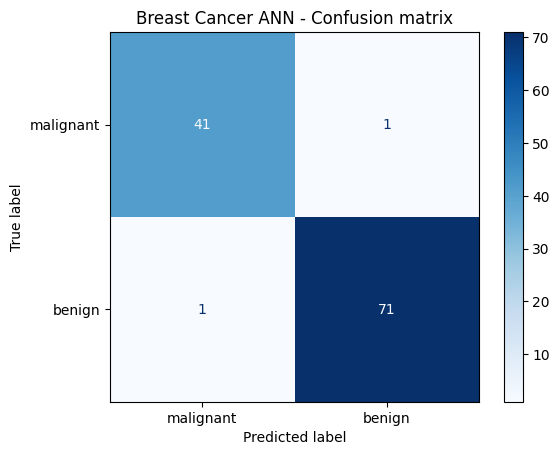

In [20]:
disp.plot(cmap=plt.cm.Blues)
plt.title("Breast Cancer ANN - Confusion matrix")
plt.show()

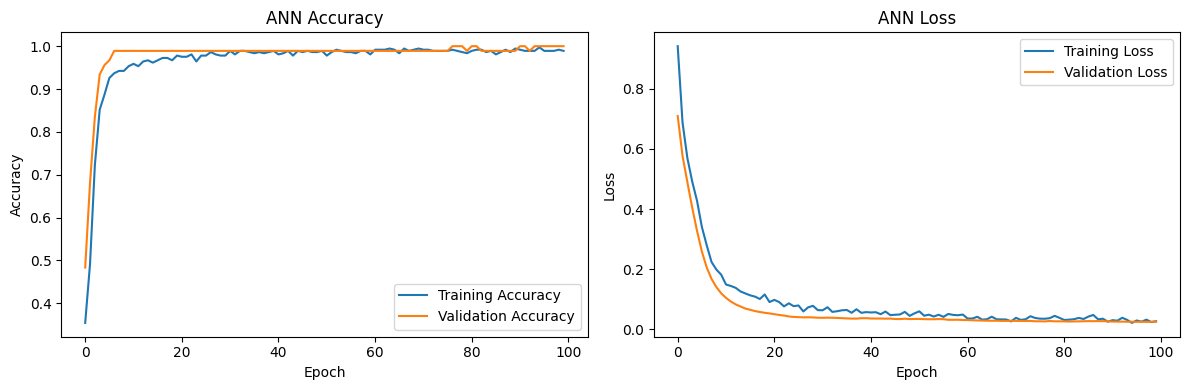

In [21]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN Loss")
plt.legend()
plt.tight_layout()
plt.show()


Training and validation performance both improve: the model may be learning useful patterns
Training improves while validation deteriorates: Possible overfitting.
Both remain poor: possible underfitting, insufficient training, or unsuitable features. 
Validation loss is used for model selection here, the test set remains reserved for final evaluation. 